# Clustering med KMeans

In [24]:
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [5]:
df = sns.load_dataset("penguins").dropna()

In [4]:
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [6]:
X = df[["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g" ]]
X.head()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,39.1,18.7,181.0,3750.0
1,39.5,17.4,186.0,3800.0
2,40.3,18.0,195.0,3250.0
4,36.7,19.3,193.0,3450.0
5,39.3,20.6,190.0,3650.0


In [8]:
X_scaled = StandardScaler().fit_transform(X)

## KMeans

In [13]:
kmeans = KMeans(n_clusters=3, random_state=42)
df["kluster"] = kmeans.fit_predict(X_scaled)

In [16]:
pd.crosstab(df["species"], df["kluster"])

kluster,0,1,2
species,,,
Adelie,124,0,22
Chinstrap,5,0,63
Gentoo,0,119,0


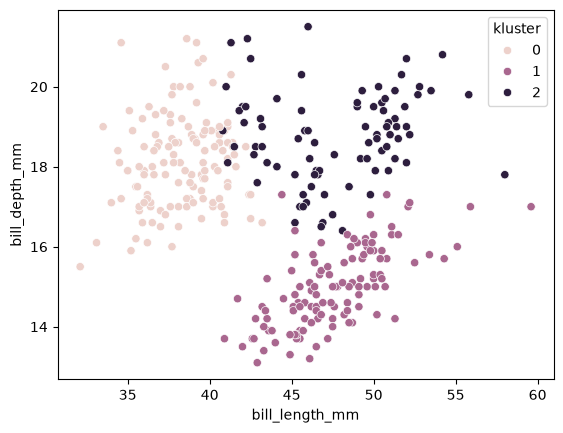

In [18]:
sns.scatterplot(data=df, x="bill_length_mm", y="bill_depth_mm", hue="kluster");

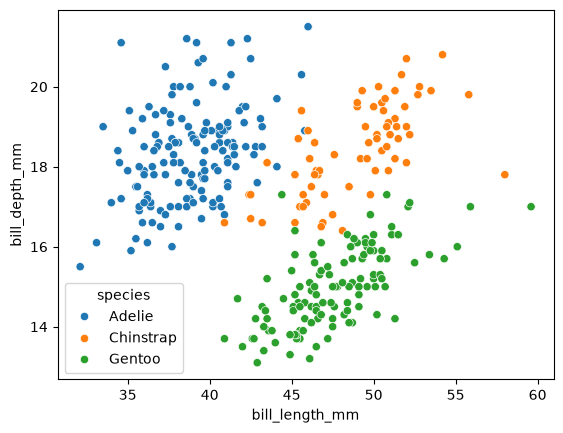

In [19]:
sns.scatterplot(data=df, x="bill_length_mm", y="bill_depth_mm", hue="species");

## Vad händer utan Scaling?

In [20]:
X.std()

bill_length_mm         5.468668
bill_depth_mm          1.969235
flipper_length_mm     14.015765
body_mass_g          805.215802
dtype: float64

In [21]:
df["kluster_unscaled"] = kmeans.fit_predict(X)

In [22]:
pd.crosstab(df["species"], df["kluster_unscaled"])

kluster_unscaled,0,1,2
species,,,
Adelie,94,0,52
Chinstrap,46,0,22
Gentoo,0,80,39


## tolka klustren

In [23]:
df.groupby("kluster")[X.columns].mean()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
kluster,,,,
0,38.276744,18.121705,188.627907,3593.798450
1,47.568067,14.996639,217.235294,5092.436975
2,47.662353,18.748235,196.917647,3898.235294


Kluster 0 - små pingviner med kort och djup näbb och korta fenor
Kluster 1 - Stora pingviner med lång och smal näbb och långa fenor
KLuster 2 - Medelstora pingviner med lång och djup näbb

In [29]:
inertia = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=42).fit(X_scaled)
    inertia.append(km.inertia_)
    print(k, round(km.inertia_), round(silhouette_score(X_scaled, km.labels_),2))
    

2 553 0.53
3 371 0.45
4 305 0.42
5 229 0.37
6 201 0.37
7 187 0.35
8 167 0.3


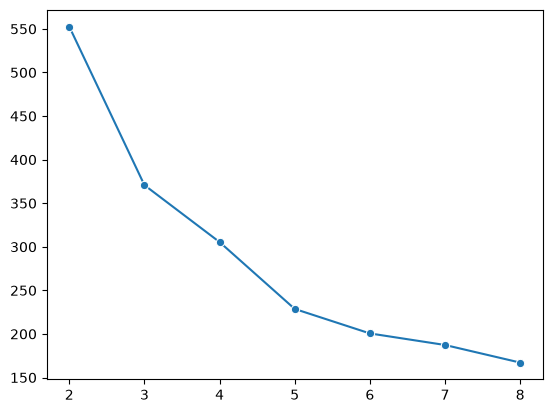

In [31]:
sns.lineplot(x=range(2,9), y=inertia, marker="o");

In [33]:
pd.crosstab([df["species"], df["sex"]], KMeans(n_clusters=6, random_state=42).fit_predict(X_scaled))

col_0              0   1   2   3   4   5
species   sex                           
Adelie    Female  71   0   2   0   0   0
          Male    14   0  57   0   0   2
Chinstrap Female   2   0   0   4   0  28
          Male     0   0   0  31   0   3
Gentoo    Female   0   2   0   0  56   0
          Male     0  52   0   0   9   0